In [31]:
from llm.model import llm_model
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator

In [32]:
model = llm_model()

In [33]:
class Evalution_schema(BaseModel):

    feedback: str = Field(description="Detailed feedback for the essay")
    score: int = Field(description="Score out of 10", ge=0, le=10)
    

In [34]:
structure_model = model.with_structured_output(Evalution_schema)

In [35]:
essay = """
**The Rise of Artificial Intelligence: A Global Revolution**

**Introduction:**
The rise of artificial intelligence (AI) is a phenomenon that has been unfolding over the past few decades, transforming the way we live, work, and interact with technology. This blog aims to provide a detailed look at the impact of AI on industries, society, and the future of AI, encouraging readers to embrace this transformative technology responsibly.

**Section 1: The Impact of AI on Industries**

**Healthcare**
- **AI in diagnostics**: AI algorithms can analyze medical images and patient data to identify diseases earlier and with greater accuracy than human doctors.
- **AI in drug discovery**: AI can accelerate the drug discovery process by predicting the efficacy and side effects of new compounds, reducing the time and cost of bringing new drugs to market.
- **AI in personalized medicine**: AI can tailor treatments to individual patients based on their genetic makeup, medical history, and lifestyle, leading to more effective and personalized care.

**Finance**
- **AI in trading**: AI can analyze market trends and make predictions about future prices, allowing traders to make informed decisions.
- **AI in risk management**: AI can identify potential risks in financial markets and help organizations mitigate them.
- **AI in fraud detection**: AI can detect fraudulent activities by analyzing patterns and anomalies in financial transactions, helping organizations protect their customers and assets.

**Retail**
- **AI in customer service**: AI chatbots can provide 24/7 customer support, answering questions and resolving issues quickly.
- **AI in inventory management**: AI can predict demand and optimize inventory levels, reducing waste and improving cash flow.
- **AI in personalized marketing**: AI can analyze customer behavior and preferences to deliver personalized marketing messages, increasing the effectiveness of marketing campaigns.

**Manufacturing**
- **AI in quality control**: AI can monitor manufacturing processes and detect defects early, improving product quality and reducing waste.
- **AI in predictive maintenance**: AI can predict equipment failures before they occur, reducing downtime and maintenance costs.
...
- **AI in everyday consumer products**: AI can provide personalized experiences, improving customer satisfaction and loyalty.

**Conclusion:**
The rise of AI is transforming the way we live, work, and interact with technology. It is reshaping industries, improving society, and creating new opportunities for innovation. As AI continues to advance, it is essential that we embrace this transformative technology responsibly, ensuring that it is used for the benefit of society and not for harm. By understanding the impact of AI on industries and society, and by staying informed about the future of AI, we can harness the power of this technology to create a better world for all.
"""

In [36]:
prompt = f'Evalute the language quality of the following essay and provide a feedback and assign a score out of 10 \n {essay}'

structure_model.invoke(prompt).score

9

In [37]:
class UPSCState(TypedDict):

    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add]
    avg_score: float


In [38]:
def evalute_language(state: UPSCState):

    prompt = f'Evalute the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output  = structure_model.invoke(prompt)

    return {'language_feedback': output.feedback, 'individual_scores': [output.score]}


In [39]:
def evalute_analysis(state: UPSCState):

    prompt = f'Evalute the depth of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output  = structure_model.invoke(prompt)

    return {'analysis_feedback': output.feedback, 'individual_scores': [output.score]}


In [40]:
def evalute_thought(state: UPSCState):

    prompt = f'Evalute the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'
    output  = structure_model.invoke(prompt)

    return {'clarity_feedback': output.feedback, 'individual_scores': [output.score]}


In [41]:
def final_evalution(state: UPSCState):

    # summary feedback 
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'

    overall_feedback = model.invoke(prompt).content

    # avg calculate
    avg_score = sum(state['individual_scores']) / len(state['individual_scores'])

    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}

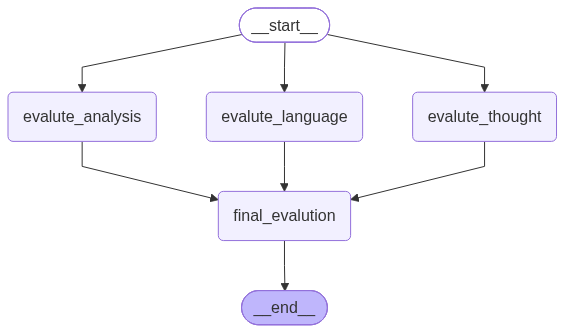

In [44]:
graph = StateGraph(UPSCState)

graph.add_node('evalute_language', evalute_language)
graph.add_node('evalute_analysis', evalute_analysis)
graph.add_node('evalute_thought', evalute_thought)
graph.add_node('final_evalution', final_evalution)

# edges
graph.add_edge(START, 'evalute_language')
graph.add_edge(START, 'evalute_analysis')
graph.add_edge(START, 'evalute_thought')

graph.add_edge('evalute_language', 'final_evalution')
graph.add_edge('evalute_analysis', 'final_evalution')
graph.add_edge('evalute_thought', 'final_evalution')

graph.add_edge('final_evalution', END)

workflow = graph.compile()

workflow


In [45]:
initial_state = {
    'essay': essay
}

workflow.invoke(initial_state)

{'essay': '\n**The Rise of Artificial Intelligence: A Global Revolution**\n\n**Introduction:**\nThe rise of artificial intelligence (AI) is a phenomenon that has been unfolding over the past few decades, transforming the way we live, work, and interact with technology. This blog aims to provide a detailed look at the impact of AI on industries, society, and the future of AI, encouraging readers to embrace this transformative technology responsibly.\n\n**Section 1: The Impact of AI on Industries**\n\n**Healthcare**\n- **AI in diagnostics**: AI algorithms can analyze medical images and patient data to identify diseases earlier and with greater accuracy than human doctors.\n- **AI in drug discovery**: AI can accelerate the drug discovery process by predicting the efficacy and side effects of new compounds, reducing the time and cost of bringing new drugs to market.\n- **AI in personalized medicine**: AI can tailor treatments to individual patients based on their genetic makeup, medical hi